# Trabajo Integrador

## Proyecto Final: Evaluación Estudiantil

### Descripción del Proyecto

Desarrollar un **sistema de gestión** académica **que permita analizar** las notas de los **estudiantes** en seis cursos diferentes. Dicho sistema debería poder **calcular** el promedio de notas (con aplazos y sin aplazos), determinar la situación académica de cada estudiante (aprobado o reprobado) y **mostrar la información** general de las notas.

Decidimos trabajarlo en forma paralela mediante: 
* python vanilla orientado a objetos y
* pandas

y de esa forma poder comparar resultados.

### Librerias

In [60]:
import pandas as pd
import matplotlib.pyplot as plt
import csv
from enum import Enum
import random
from faker import Faker

In [61]:
class Constantes:

    INTERNACIONALIZACION = 'es_ES'
    NOTA_MINIMA_APROBACION = 6
    RUTA_ARCHIVO = 'estudiantes.csv'
    NOMBRES_COLUMNAS = ['nombre', 'apellido', 'programacion', 'bases_de_datos', 'estadistica', 'arq_nube', 'ap_automatico', 'cap_informacion']
    CANT_FILAS = 5
    CANT_DECIMALES = 2

### Generación de datos

* Tener en cuenta que al ejecutar la celda:
    * si no existe el archivo de datos lo crea
    * si existe sobreescribe

In [62]:
class GeneracionDatos:

    def __init__(self, nombres_columnas, cantidad_filas, internacionalizacion):
        self.__nombres_columnas = nombres_columnas
        self.__cantidad_filas = cantidad_filas
        self.__internacionalizacion = internacionalizacion

    def escribir_csv(self, ruta):
        fake = Faker(self.__internacionalizacion)
        archivo = open(ruta, 'w')
        archivo.write(','.join(self.__nombres_columnas) + '\n')
        for _ in range(self.__cantidad_filas):
            fila = [fake.first_name(), fake.last_name()]
            for _ in range(6):
                fila.append(str(random.randint(1, 10)))
            archivo.write(','.join(fila) + '\n')
        archivo.close()   

In [63]:
generacion_datos = GeneracionDatos(Constantes.NOMBRES_COLUMNAS, Constantes.CANT_FILAS, Constantes.INTERNACIONALIZACION)
generacion_datos.escribir_csv(Constantes.RUTA_ARCHIVO)

### Modelado Orientado a Objetos

In [64]:
class EstadoAcademico(Enum):
    
    APROBADO = 'aprobado'
    REPROBADO = 'reprobado'

In [68]:
class Estudiante:

    def __init__(self, nombre, apellido):
        self.__nombre = nombre
        self.__apellido = apellido
        self.__notas = {}

    def get_nombre(self):
        return self.__nombre

    def get_apellido(self):
        return self.__apellido

    def get_notas(self):
        return self.__notas

    def agregar_nota(self, materia, nota):
        self.__notas[materia] = nota

    def calcular_prom(self):
        return round(sum(self.__notas.values())/len(self.__notas), Constantes.CANT_DECIMALES)

    def obtener_sit(self):
        return EstadoAcademico.APROBADO if self.calcular_prom() >= Constantes.NOTA_MINIMA_APROBACION else EstadoAcademico.REPROBADO

    def __str__(self):
        estado = self.obtener_sit().value.upper()
        aux = f'👤 {self.get_nombre()} {self.get_apellido()} | Promedio: {self.calcular_prom():.2f} [{estado}] \n   Notas: '
        aux += ' | '.join(f'{mat}: {nota}' for mat, nota in self.get_notas().items())
        return aux

In [69]:
class GestionAcademicaVanilla:

    def __init__(self):
        self.__encabezados = []
        self.__estudiantes = []

    def leer_csv(self, ruta):
        archivo = open(ruta, newline='')
        dataset = list(csv.reader(archivo))
        self.__encabezados = dataset[0]
        datos = dataset[1:]
        for fila in datos:
            estudiante = Estudiante(fila[0], fila[1])
            for i in range(2, 8):
                estudiante.agregar_nota(self.__encabezados[i], int(fila[i]))
            self.agregar_estudiante(estudiante)

    def agregar_estudiante(self, estudiante):
        self.__estudiantes.append(estudiante)

    def get_estudiantes(self):
        return self.__estudiantes

    def promedio_asignaturas(self):
        prom_asignaturas = {}        
        for estudiante in self.__estudiantes:
            for materia, nota in estudiante.get_notas().items():
                if materia in prom_asignaturas:
                    prom_asignaturas[materia] += nota
                else:
                    prom_asignaturas[materia] = nota
        for materia, acum in prom_asignaturas.items():
            prom_asignaturas[materia] = round(acum/len(self.__estudiantes), Constantes.CANT_DECIMALES)
        return prom_asignaturas

    def promedio_asignatura(self, asignatura):
        return self.promedio_asignaturas()[asignatura]

    def porcentaje_aprobacion_general(self):
        contador_general = 0
        contador_aprobados = 0
        for estudiante in self.__estudiantes:
            for materia, nota in estudiante.get_notas().items():
                contador_general += 1
                if nota >= Constantes.NOTA_MINIMA_APROBACION:
                    contador_aprobados += 1
        return round(contador_aprobados/contador_general * 100, Constantes.CANT_DECIMALES)

    def materia_mayor_rendimiento(self): 
        promedio_asignaturas = self.promedio_asignaturas()
        return max(promedio_asignaturas, key=promedio_asignaturas.get)

    def materia_menor_rendimiento(self):
        promedio_asignaturas = self.promedio_asignaturas()
        return min(promedio_asignaturas, key=promedio_asignaturas.get)

    def mostrar_estudiantes(self):
        print('=' * 60)                                                                                       
        for est in self.__estudiantes:
            print(est)                                                              
            print('-' * 60)    

    def resumen_general_rendimiento(self):
        data = self.promedio_asignaturas()
        plt.figure(figsize=(8, 5))
        fig, ax = plt.subplots()
        ax.bar(x = data.keys(), height = data.values())
        plt.title("Promedio por materia")
        plt.xlabel("Materias")
        plt.ylabel("Promedio")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

In [70]:
gestion_academica = GestionAcademicaVanilla()
gestion_academica.leer_csv(Constantes.RUTA_ARCHIVO)
gestion_academica.mostrar_estudiantes()

👤 Jessica Arenas | Promedio: 5.50 [REPROBADO] 
   Notas: programacion: 3 | bases_de_datos: 7 | estadistica: 7 | arq_nube: 9 | ap_automatico: 4 | cap_informacion: 3
------------------------------------------------------------
👤 Inés Peiró | Promedio: 5.67 [REPROBADO] 
   Notas: programacion: 8 | bases_de_datos: 9 | estadistica: 6 | arq_nube: 6 | ap_automatico: 2 | cap_informacion: 3
------------------------------------------------------------
👤 Bautista Santiago | Promedio: 8.00 [APROBADO] 
   Notas: programacion: 9 | bases_de_datos: 6 | estadistica: 10 | arq_nube: 10 | ap_automatico: 6 | cap_informacion: 7
------------------------------------------------------------
👤 Remedios Jódar | Promedio: 5.67 [REPROBADO] 
   Notas: programacion: 10 | bases_de_datos: 10 | estadistica: 5 | arq_nube: 3 | ap_automatico: 5 | cap_informacion: 1
------------------------------------------------------------
👤 Casandra Benito | Promedio: 5.67 [REPROBADO] 
   Notas: programacion: 9 | bases_de_datos: 10 | e

In [71]:
gestion_academica.promedio_asignaturas()

{'programacion': 7.8,
 'bases_de_datos': 8.4,
 'estadistica': 7.6,
 'arq_nube': 5.8,
 'ap_automatico': 4.0,
 'cap_informacion': 3.0}

In [72]:
gestion_academica.porcentaje_aprobacion_general()

60.0

In [73]:
gestion_academica.materia_mayor_rendimiento()

'bases_de_datos'

In [74]:
gestion_academica.materia_menor_rendimiento()

'cap_informacion'

<Figure size 800x500 with 0 Axes>

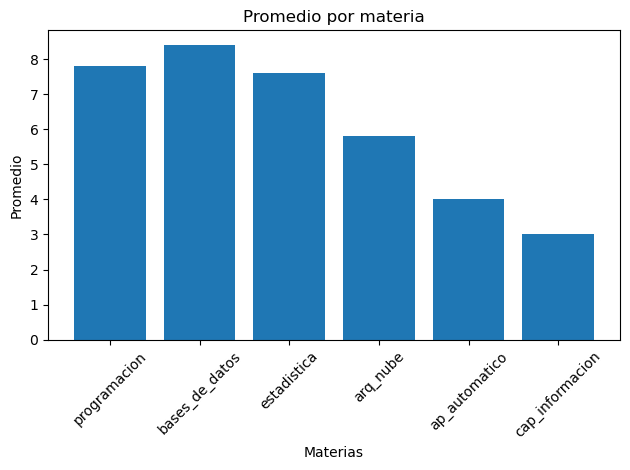

In [75]:
gestion_academica.resumen_general_rendimiento()

### Pandas

In [79]:
class GestionAcademicaPandas:

    def __init__(self):
        self.__df = None 
        self.__materias = None

    def get_df(self):
        return self.__df
        
    def leer_csv(self, ruta):
        self.__df = pd.read_csv(ruta)
        self.__materias = self.__df.columns[2:]

    def calcular_prom(self):
        self.__df['promedio'] = self.__df[self.__materias].mean(axis=1).round(Constantes.CANT_DECIMALES)

    def obtener_sit(self):
        self.__df['sit_academica'] = self.__df['promedio'].apply(lambda x: 'aprobado' if x >= Constantes.NOTA_MINIMA_APROBACION else 'desaprobado')

    def promedio_asignaturas(self):
        return self.__df.describe().loc['mean'].round(Constantes.CANT_DECIMALES)

    def porcentaje_aprobacion_general(self):
        aprobadas = (self.__df[self.__materias] >= Constantes.NOTA_MINIMA_APROBACION).sum().sum()
        total_notas = self.__df[self.__materias].size
        return round((aprobadas / total_notas) * 100, Constantes.CANT_DECIMALES) 

    def materia_mayor_rendimiento(self):
        return self.__df[self.__materias].mean().idxmax()

    def materia_menor_rendimiento(self):
        return self.__df[self.__materias].mean().idxmin()

    def resumen_general_rendimiento(self):
        promedios = self.__df[self.__materias].mean()
        plt.figure(figsize=(8, 5))
        plt.bar(promedios.index, promedios.values)
        plt.title("Promedio por materia")
        plt.xlabel("Materias")
        plt.ylabel("Promedio")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

In [80]:
gestion_academica_pandas = GestionAcademicaPandas()
gestion_academica_pandas.leer_csv(Constantes.RUTA_ARCHIVO)
gestion_academica_pandas.calcular_prom()
gestion_academica_pandas.obtener_sit()
gestion_academica_pandas.get_df()

,nombre,apellido,programacion,bases_de_datos,estadistica,arq_nube,ap_automatico,cap_informacion,promedio,sit_academica
0,Jessica,Arenas,3,7,7,9,4,3,5.50,desaprobado
1,Inés,Peiró,8,9,6,6,2,3,5.67,desaprobado
2,Bautista,Santiago,9,6,10,10,6,7,8.00,aprobado
3,Remedios,Jódar,10,10,5,3,5,1,5.67,desaprobado
4,Casandra,Benito,9,10,10,1,3,1,5.67,desaprobado


In [81]:
gestion_academica_pandas.promedio_asignaturas()

programacion       7.8
bases_de_datos     8.4
estadistica        7.6
arq_nube           5.8
ap_automatico      4.0
cap_informacion    3.0
promedio           6.1
Name: mean, dtype: float64

In [82]:
gestion_academica_pandas.porcentaje_aprobacion_general()

60.0

In [83]:
gestion_academica_pandas.materia_mayor_rendimiento()

'bases_de_datos'

In [84]:
gestion_academica_pandas.materia_menor_rendimiento()

'cap_informacion'

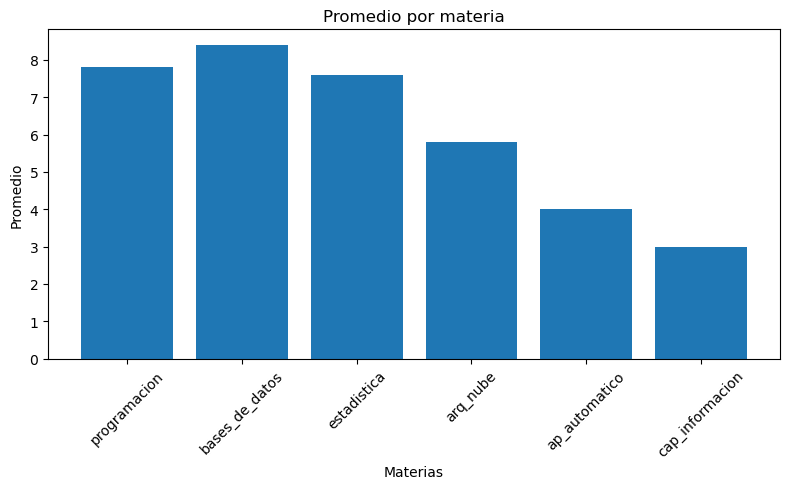

In [85]:
gestion_academica_pandas.resumen_general_rendimiento()